# Lab 4, Part 3: Cats and dogs with ResNeXt-50

I trained ResNeXt-50 32x4d from scratch using Torchvision with `weights=None`. The network outputs one logit per image. Applying sigmoid gives the estimated probability that the image shows a dog.

Run all cells to evaluate the included weights. Set `RUN_TRAINING = True` in section 3 to train again.

## 1. Dataset

The original train, validation, and test splits are used as supplied. Cats are class 0 and dogs are class 1. Files are sorted by name within each class.

In [1]:
import hashlib
import json
import os
from pathlib import Path
import subprocess
import sys

import matplotlib.pyplot as plt
import numpy as np
import torch

ROOT = Path.cwd()
if not (ROOT / 'model_ema.pt').is_file():
    ROOT = ROOT / 'PART3_ResNeXt50'
if not (ROOT / 'model_ema.pt').is_file():
    raise FileNotFoundError('Open this notebook from the PART3_ResNeXt50 folder.')
sys.path.insert(0, str(ROOT))

import part3_cache
import part3_train
import resnext50

DATA = ROOT / 'Cats_and_Dogs'
CACHE = Path(os.environ.get('PART3_NOTEBOOK_CACHE', str(ROOT / 'cache')))
WEIGHTS = ROOT / 'model_ema.pt'
EXTENSIONS = {'.jpg', '.jpeg', '.png'}
SPLITS = ('train', 'val', 'test')
CLASSES = ('cats', 'dogs')

def image_paths(split, cls):
    return sorted(path for path in (DATA / split / cls).iterdir()
                  if path.suffix.lower() in EXTENSIONS)

for split in SPLITS:
    counts = [len(image_paths(split, cls)) for cls in CLASSES]
    print(f'{split:5} | cats {counts[0]:5} | dogs {counts[1]:5} | total {sum(counts):5}')

train | cats 10000 | dogs 10000 | total 20000
val   | cats  1240 | dogs  1250 | total  2490
test  | cats  1250 | dogs  1250 | total  2500


## 2. Preprocessing

Images are converted to RGB and resized to 288 x 288 before caching. Training uses random crops, horizontal flips, and changes to brightness, contrast, and saturation. The crop size grows from 160 to 224 px. Some batches use MixUp or CutMix, and the training labels are smoothed.

At evaluation time, the model sees the full 288 x 288 image and its horizontal flip. I average the two logits, apply sigmoid, and classify probabilities above 0.5 as dog.

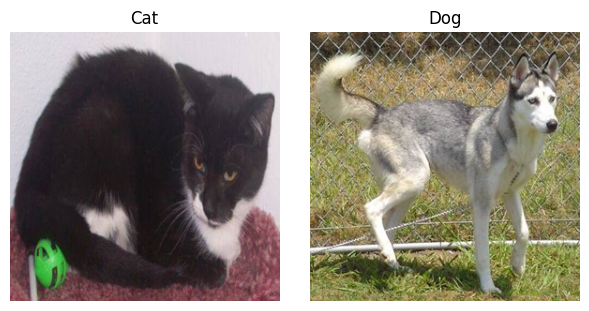

In [2]:
def preprocess_image(path):
    pixels = part3_cache._load((Path(path), 288, False))
    return torch.from_numpy(pixels.copy()).unsqueeze(0)

examples = [image_paths('val', cls)[0] for cls in CLASSES]
fig, axes = plt.subplots(1, 2, figsize=(6, 3), layout='constrained')
for ax, path, label in zip(axes, examples, ('Cat', 'Dog')):
    ax.imshow(preprocess_image(path)[0])
    ax.set_title(label)
    ax.axis('off')
plt.show()

## 3. Training

I trained all layers for 250 epochs on the training split. The loss was binary cross-entropy with logits. I used SGD with Nesterov momentum, five warmup epochs, and cosine learning rate decay. The final evaluation uses EMA weights, an exponential moving average of the weights from this run.

If enabled, the training cell saves its checkpoints and weights in `notebook_retrain/`.

In [3]:
RUN_TRAINING = False
RETRAINED = ROOT / 'notebook_retrain'

history_file = ROOT / 'training_log.json'
history = json.loads(history_file.read_text(encoding='utf-8'))
recipe = history['args']
for name in ('arch', 'seed', 'epochs', 'bs', 'optimizer', 'lr', 'warmup',
             'res_start', 'res', 'test_res', 'mix_prob', 'smoothing', 'ema'):
    print(f'{name:12} {recipe[name]}')

if RUN_TRAINING:
    subprocess.run([sys.executable, str(ROOT / 'resnext50.py'), 'train',
                    '--data', str(DATA), '--cache', str(CACHE),
                    '--out', str(RETRAINED)], cwd=ROOT, check=True)
    WEIGHTS = RETRAINED / 'model_ema.pt'
    history = json.loads((RETRAINED / 'log.json').read_text(encoding='utf-8'))

arch         resnext50_32x4d
seed         0
epochs       250
bs           128
optimizer    sgd
lr           0.1
warmup       5
res_start    160
res          224
test_res     288
mix_prob     0.5
smoothing    0.1
ema          0.9995


## 4. Learning curves

Validation ran every five epochs. The training loss includes augmented images and mixed labels.

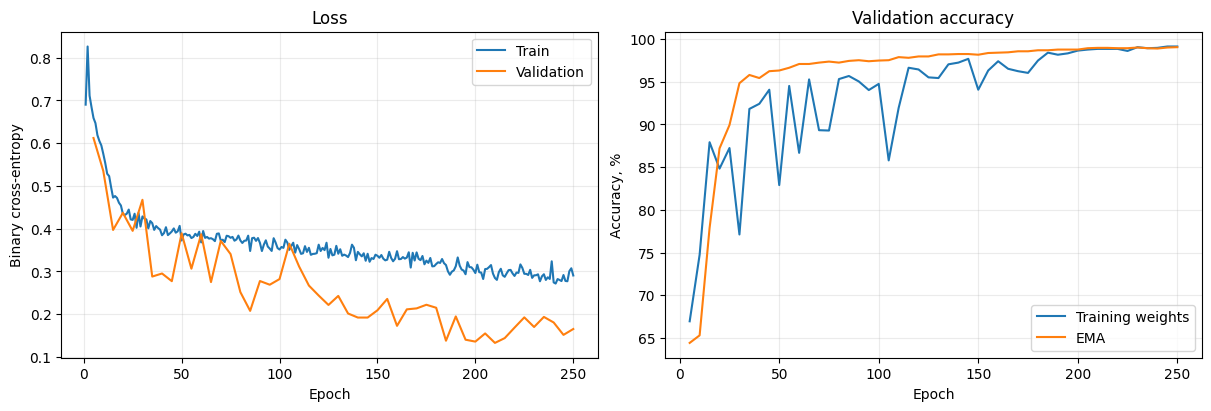

In [4]:
epochs = np.array(history['epoch'])
val_ema = np.array(history['val_acc_ema'], dtype=float)
val_raw = np.array(history['val_acc'], dtype=float)
val_loss = np.array(history['val_loss'], dtype=float)

fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout='constrained')
axes[0].plot(epochs, history['train_loss'], label='Train')
axes[0].plot(epochs[np.isfinite(val_loss)], val_loss[np.isfinite(val_loss)], label='Validation')
axes[0].set(xlabel='Epoch', ylabel='Binary cross-entropy', title='Loss')
for values, label in ((val_raw, 'Training weights'), (val_ema, 'EMA')):
    mask = np.isfinite(values)
    axes[1].plot(epochs[mask], values[mask], label=label)
axes[1].set(xlabel='Epoch', ylabel='Accuracy, %', title='Validation accuracy')
for ax in axes:
    ax.legend()
    ax.grid(alpha=0.25)
plt.show()

## 5. Evaluation

The contest score is accuracy on the original test split. This cell runs the saved model on both the validation and test images.

In [5]:
device = part3_train.get_device()
model = resnext50.load_model(WEIGHTS, device)
print(f'Device: {device.type}')

metrics = {}
for split in ('val', 'test'):
    part3_cache.build(DATA, CACHE, split, 288)
    images, labels = part3_train.load_split(CACHE, split, 288)
    probability = part3_train.predict(model, images, device=device, bs=32, res=288)
    prediction = (probability > 0.5).astype(np.int64)
    y = labels.numpy()
    correct = int(np.count_nonzero(prediction == y))
    metrics[split] = {'accuracy': correct / len(y), 'correct': correct, 'size': len(y)}
    print(f'{split:4} | accuracy {correct / len(y):.4f} | {correct}/{len(y)} correct | {len(y) - correct} errors')

test_labels, test_prediction = y, prediction

Device: cuda
..\cache_pc\val_288.npz already exists, skip


val  | accuracy 0.9892 | 2463/2490 correct | 27 errors
..\cache_pc\test_288.npz already exists, skip


test | accuracy 0.9912 | 2478/2500 correct | 22 errors


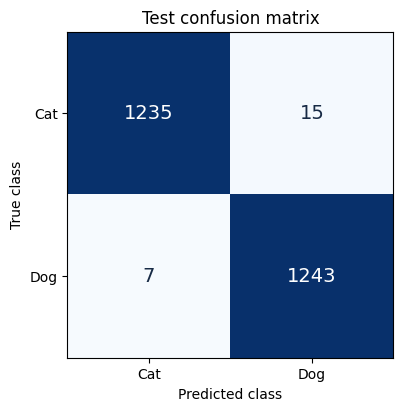

Cats | recall 0.9880
Dogs | recall 0.9944


In [6]:
cm = np.bincount(2 * test_labels + test_prediction, minlength=4).reshape(2, 2)
fig, ax = plt.subplots(figsize=(4.8, 4), layout='constrained')
im = ax.imshow(cm, cmap='Blues', vmin=0)
for row, col in np.ndindex(cm.shape):
    color = 'white' if cm[row, col] > cm.max() / 2 else '#172a45'
    ax.text(col, row, str(cm[row, col]), ha='center', va='center', color=color, fontsize=14)
ax.set(xticks=[0, 1], yticks=[0, 1], xticklabels=['Cat', 'Dog'],
       yticklabels=['Cat', 'Dog'], xlabel='Predicted class',
       ylabel='True class', title='Test confusion matrix')
plt.show()

for label, name in enumerate(('Cats', 'Dogs')):
    print(f'{name} | recall {cm[label, label] / cm[label].sum():.4f}')

## Conclusion

ResNeXt-50 scored **0.9912** on the original test split at 288 px, with **2,478 correct predictions out of 2,500**. The model was trained from scratch for 250 epochs.